# 07. Load vs velocity

*The load model we keep uses the **mission line speed** with one k per mode: see **nb 08 (load vs mission)**. This notebook fits the motor on the per-minute speed over ground, and its section 5 still uses the old 1 m/s waypoint plan.*

**Part 1. Analysis**
1. Raw electrical data: voltage, current, power
2. Propulsion power vs speed, by mode (hotel and Starlink from nb 06)

**Part 2. Model**
3. load = P_hotel + P_starlink · Starlink + k · v³, then the final parameters
3b. Two more shapes for the motor: k · v and k · v², compared with k · v³

**Part 3. Prediction**
4. Load estimated from speed over ground and Starlink on/off only, compared with the measured load
5. Load estimated from the plan only (Starlink sessions + 1 m/s motor runs, nb 05/04), compared with the measured load
6. Predictions with all three motor models (k·v, k·v², k·v³), from telemetry and from the plan

Channels: battery1 = battery, battery2 ("thruster" in Tether) = total load, battery3 = solar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_batt"] = df.voltage_battery1_v * df.current_battery1_a     # W, + = charging
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, solar in

LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
POWER_COLORS = {"P_solar": "#f2b701", "P_load": "#d62728", "P_batt": "#1f77b4"}
POWER_NAMES = {"P_solar": "solar in", "P_load": "load out", "P_batt": "battery net (+ charging)"}
MODE_NAMES = {0: "MANUAL", 10: "AUTO", 17: "mode 17"}
SL_COLORS = {False: "#ff7f0e", True: "#1f77b4"}
SL_NAMES = {False: "Starlink off", True: "Starlink on"}
START, END = pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC")

def daily_axis(ax):
    ax.set_xlim(START, END)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Part 1. Analysis

## 1. Voltage

Every row, coloured by link.

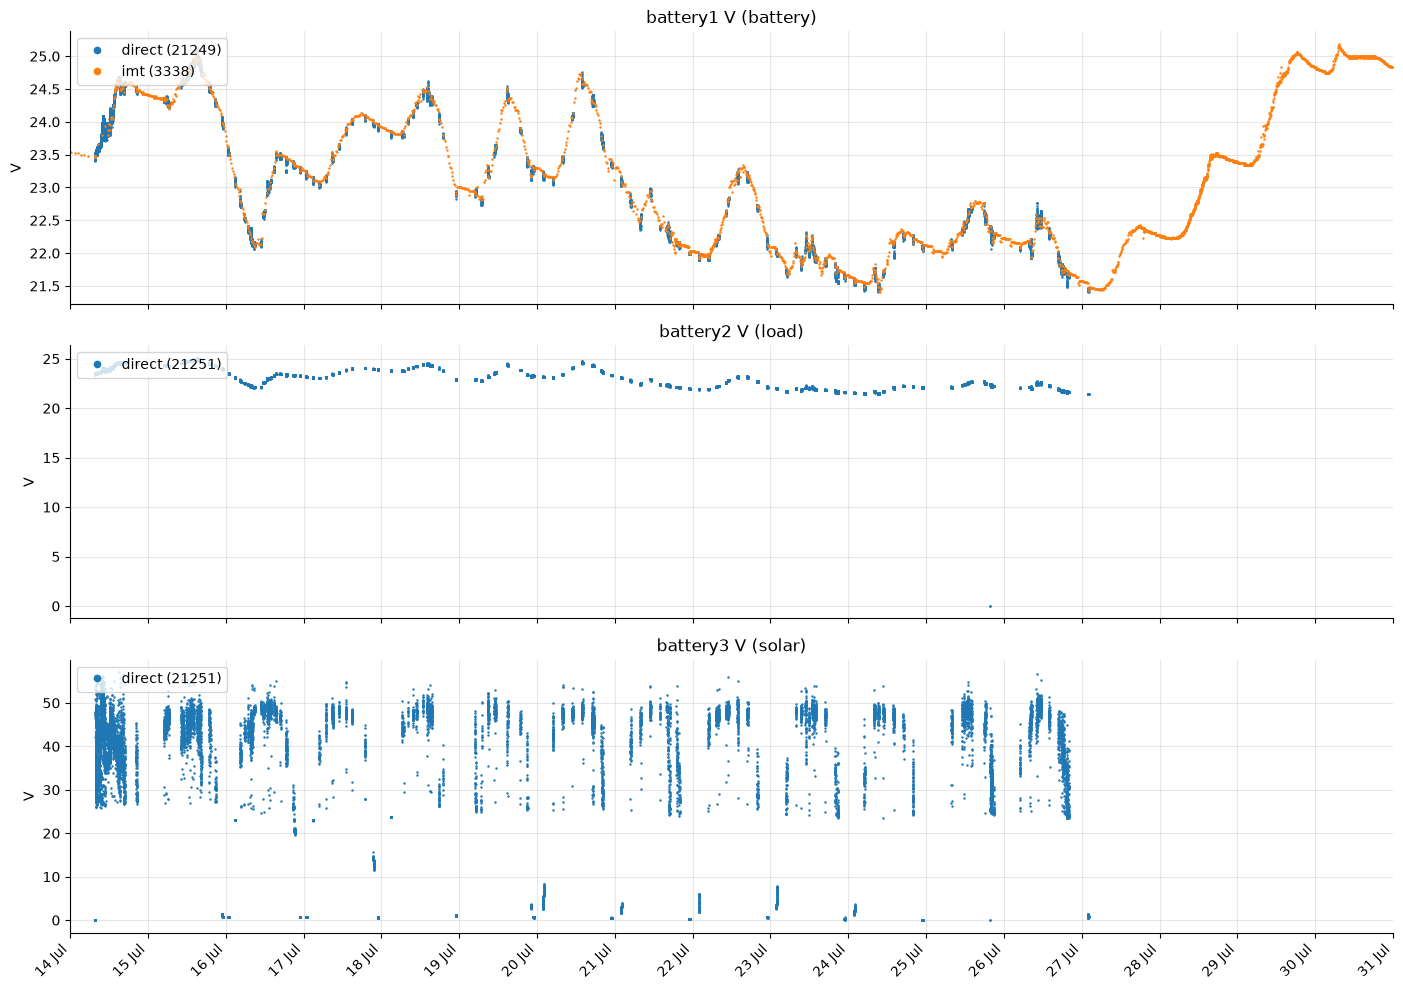

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, title in zip(axes, ["voltage_battery1_v", "voltage_battery2_v", "voltage_battery3_v"],
                          ["battery1 V (battery)", "battery2 V (load)", "battery3 V (solar)"]):
    for link, g in df.dropna(subset=[col]).groupby("communication_mode"):
        ax.plot(g.t, g[col], ".", ms=1.5, color=LINK_COLORS[link], label=f"{link} ({len(g)})")
    ax.set_title(title); ax.set_ylabel("V"); ax.legend(markerscale=6, loc="upper left")
daily_axis(axes[-1])
plt.tight_layout(); plt.show()

## 1b. Current

Every row, coloured by link. Battery current: + = charging.

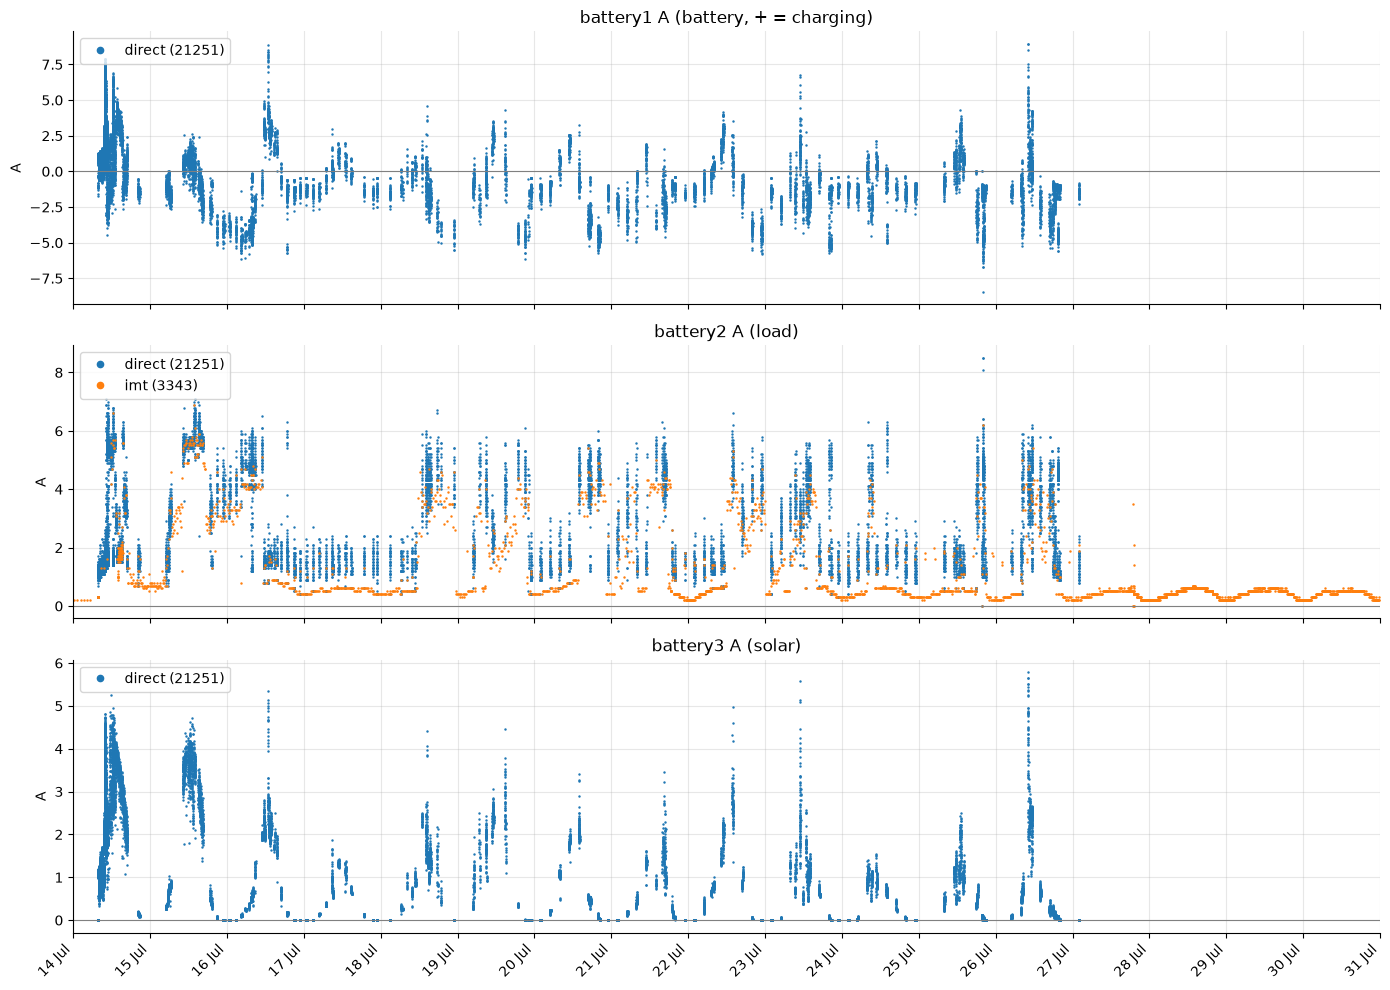

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, title in zip(axes, ["current_battery1_a", "current_battery2_a", "current_battery3_a"],
                          ["battery1 A (battery, + = charging)", "battery2 A (load)", "battery3 A (solar)"]):
    for link, g in df.dropna(subset=[col]).groupby("communication_mode"):
        ax.plot(g.t, g[col], ".", ms=1.5, color=LINK_COLORS[link], label=f"{link} ({len(g)})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(title); ax.set_ylabel("A"); ax.legend(markerscale=6, loc="upper left")
daily_axis(axes[-1])
plt.tight_layout(); plt.show()

## 1c. Power

Power = V × I. Load power uses battery1 V (battery2 V only comes over Starlink).

The last panel is **PV − load**: solar in minus load out, Starlink rows only (the only ones with solar).

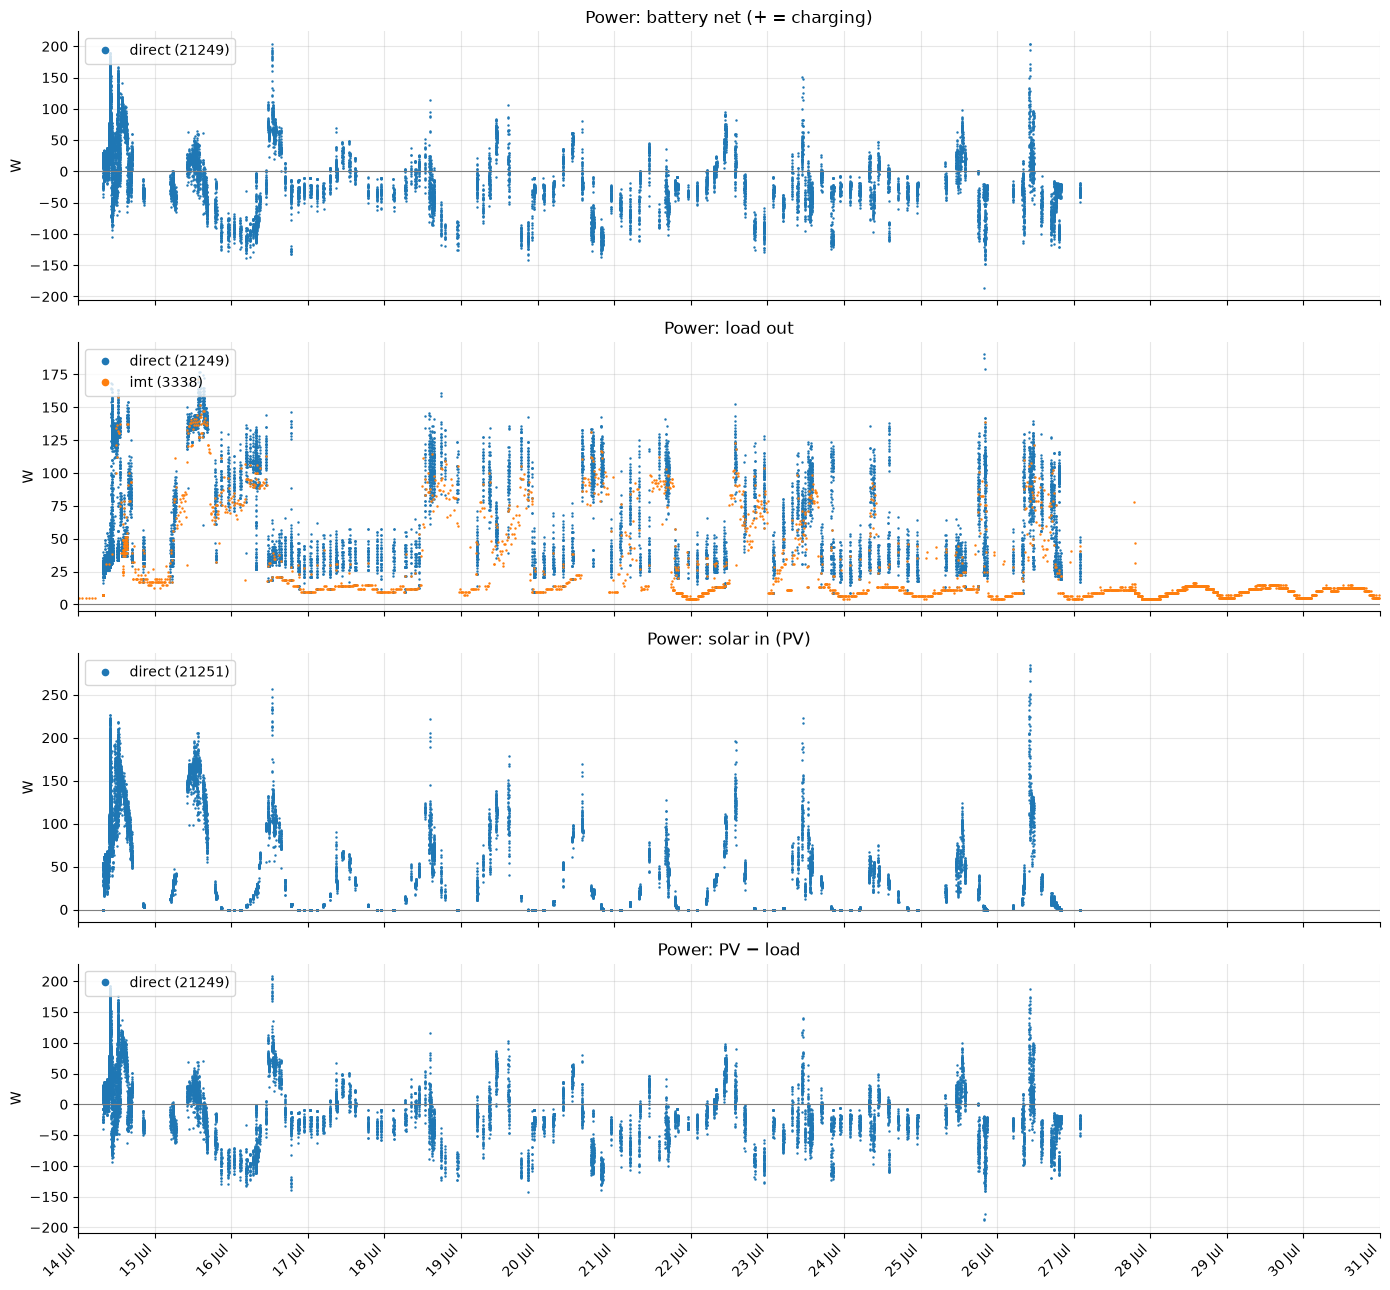

In [4]:
df["PV_minus_load"] = df.P_solar - df.P_load
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)
panels = [("P_batt", "battery net (+ = charging)"), ("P_load", "load out"), ("P_solar", "solar in (PV)"),
          ("PV_minus_load", "PV − load")]
for ax, (col, title) in zip(axes, panels):
    for link, g in df.dropna(subset=[col]).groupby("communication_mode"):
        ax.plot(g.t, g[col], ".", ms=1.5, color=LINK_COLORS[link], label=f"{link} ({len(g)})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"Power: {title}"); ax.set_ylabel("W"); ax.legend(markerscale=6, loc="upper left")
daily_axis(axes[-1])
plt.tight_layout(); plt.show()

## 2. Propulsion power

Hotel (10 W) and Starlink (22 W) come from **nb 06** (MANUAL, motor off). Taking both off the load leaves the motor:

**propulsion = load − 10 W − 22 W × (Starlink on)**

**One point per minute:** Starlink sends every 1 s on some days and 15 s on others, so raw rows would over-weight those days. Load and speed are averaged per minute; mode is the last one in the minute. "Starlink on" = inside a Starlink session (messages < 2 min apart) ± 30 s.

In [5]:
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
pad = pd.Timedelta("30s")
df["starlink"] = False
for start, end in sessions.itertuples(index=False):
    df.loc[df.t.between(start - pad, end + pad), "starlink"] = True

m = (df.dropna(subset=["P_load"]).set_index("t").resample("1min")
       .agg({"P_load": "mean", "groundspeed_ms": "mean", "custom_mode": "last", "custom0_arming": "last", "starlink": "max"})
       .dropna(subset=["P_load"]).reset_index())
m["starlink"] = m.starlink.astype(bool)
m["armed"] = m.custom0_arming == 1

# MANUAL split by arming (disarmed = motor can't run at all); AUTO / mode 17 are armed except a minute or two
GROUP_NAMES = ["MANUAL disarmed", "MANUAL armed", "AUTO", "mode 17"]
GROUP_COLORS = {"MANUAL disarmed": "#c7c7c7", "MANUAL armed": "#7f7f7f", "AUTO": "#2ca02c", "mode 17": "#d62728"}
m["group"] = np.select([(m.custom_mode == 0) & ~m.armed, (m.custom_mode == 0) & m.armed, m.custom_mode == 10, m.custom_mode == 17],
                       GROUP_NAMES, default="other")
modes = [0, 10, 17]
BINS = np.arange(-0.1, 2.61, 0.2)                               # 0.2 m/s bins centred on 0, 0.2, 0.4… (Iridium speed steps)

HOTEL_W, STARLINK_W = 10, 22                                    # nb 06 (MANUAL, motor off)
m["P_prop"] = m.P_load - HOTEL_W - STARLINK_W * m.starlink      # propulsion = what's left of the load


### Speed over ground → propulsion power, one curve per mode

The Starlink off and on minutes now overlap, so they're merged into one set per mode. Line = median per 0.2 m/s bin, band = middle 50% (25th–75th percentile). Bins with fewer than 15 minutes are left out. X axis cropped at 2 m/s.

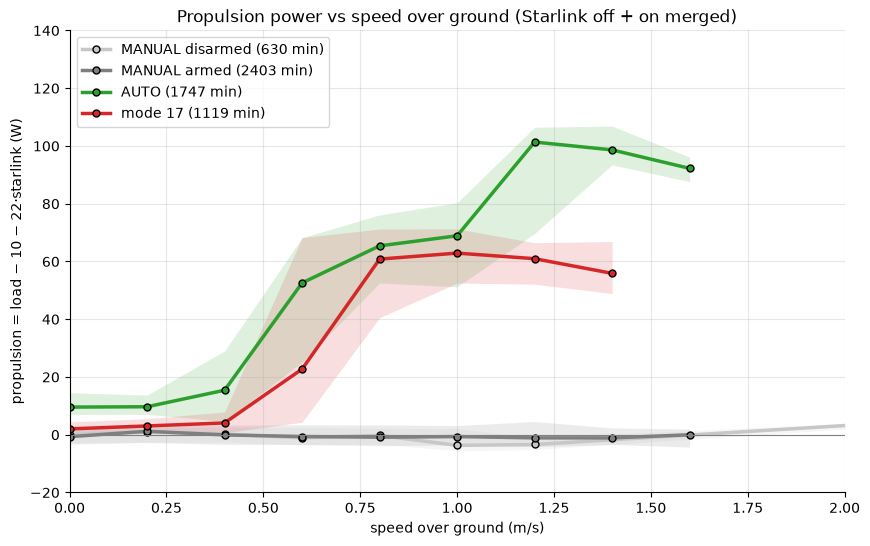

MANUAL disarmed        MANUAL armed          AUTO        mode 17       
             median      n       median      n median      n  median      n
x                                                                          
0.0             0.0   66.0         -1.0  253.0   10.0   62.0     2.0   43.0
0.2             1.0  125.0          1.0  446.0   10.0  206.0     3.0  194.0
0.4             0.0  176.0         -0.0  518.0   15.0   89.0     4.0  252.0
0.6            -1.0  104.0         -1.0  451.0   53.0  153.0    23.0  143.0
0.8            -0.0   64.0         -1.0  310.0   65.0  247.0    61.0  168.0
1.0            -4.0   34.0         -1.0  190.0   69.0  398.0    63.0  166.0
1.2            -3.0   21.0         -1.0  110.0  101.0  368.0    61.0   93.0
1.4             NaN    NaN         -1.0   50.0   99.0  200.0    56.0   44.0
1.6             NaN    NaN         -0.0   27.0   92.0   21.0     NaN    NaN
2.2             5.0   18.0          NaN    NaN    NaN    NaN     NaN    NaN

In [6]:
MODE_COLORS = {0: "#9e9e9e", 10: "#2ca02c", 17: "#d62728"}

def curve(d, min_n=15):
    g = d.groupby(pd.cut(d.groundspeed_ms, BINS), observed=False).P_prop
    out = pd.DataFrame({"x": [b.mid for b in g.median().index], "q25": g.quantile(0.25).values,
                        "median": g.median().values, "q75": g.quantile(0.75).values, "n": g.size().values})
    return out[out.n >= min_n]

curves = {grp: curve(m[m.group == grp]) for grp in GROUP_NAMES}
fig, ax = plt.subplots(figsize=(10, 6))
for grp, cv in curves.items():
    ax.fill_between(cv.x, cv.q25, cv.q75, color=GROUP_COLORS[grp], alpha=0.15, lw=0)
    ax.plot(cv.x, cv["median"], "-o", ms=5, lw=2.5, color=GROUP_COLORS[grp], mec="k",
            label=f"{grp} ({(m.group == grp).sum()} min)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 2); ax.set_ylim(-20, 140)
ax.set_xlabel("speed over ground (m/s)"); ax.set_ylabel("propulsion = load − 10 − 22·starlink (W)")
ax.set_title("Propulsion power vs speed over ground (Starlink off + on merged)")
ax.legend(loc="upper left")
plt.show()
pd.concat({k: v.set_index("x")[["median", "n"]] for k, v in curves.items()}, axis=1).sort_index().round(0)

### Speed per unit of load, Starlink removed

Speed over ground divided by the load with Starlink taken out:

**speed per W = speed over ground / (load − 22 W × Starlink on)**

The 10 W hotel load stays in the denominator. Taking it out too would leave ~0 W in MANUAL and the ratio would blow up. Units are m/s per W (× 3.6 = km per Wh). This uses every row, not per-minute means, because the map below needs each row's position. The row-level Starlink flag is the same one used above.

Some rows have load − 22 W ≤ 0 (Starlink flagged on, but the load is below 22 W). There the ratio is negative or infinite, so they sit below the cropped axis, and their count is in the title.

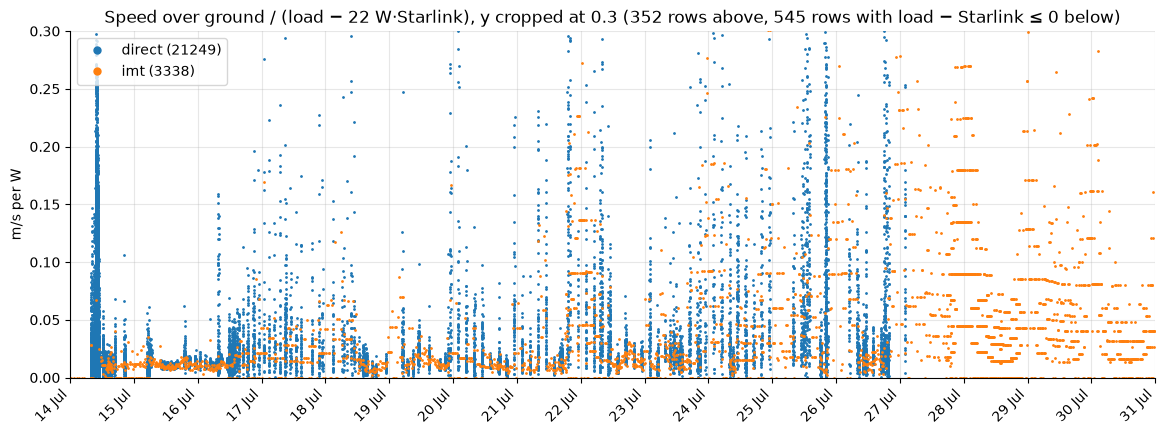

In [7]:
df["P_no_sl"] = df.P_load - STARLINK_W * df.starlink
df["speed_per_w"] = df.groundspeed_ms / df.P_no_sl
YMAX = 0.3
n_low = ((df.P_no_sl <= 0) & df.groundspeed_ms.notna()).sum()
n_high = (df.speed_per_w > YMAX).sum()
fig, ax = plt.subplots()
for link, g in df.dropna(subset=["speed_per_w"]).groupby("communication_mode"):
    ax.plot(g.t, g.speed_per_w, ".", ms=2, color=LINK_COLORS[link], label=f"{link} ({len(g)})")
ax.set_ylim(0, YMAX)
ax.set_ylabel("m/s per W")
ax.set_title(f"Speed over ground / (load − 22 W·Starlink), y cropped at {YMAX} "
             f"({n_high} rows above, {n_low} rows with load − Starlink ≤ 0 below)")
ax.legend(markerscale=5, loc="upper left")
daily_axis(ax)
plt.show()

### Same thing on the track

The colour scale stops at 0.1 m/s per W (about 90% of rows are below it), so anything higher shows as the top colour. Rows with load − Starlink ≤ 0 are drawn as red crosses instead of getting a colour. Rows with no speed or no load (globalstar) are small grey crosses. Points are drawn in time order, so where the track crosses itself the later pass is on top. The map window is set from the non-(0, 0) fixes.

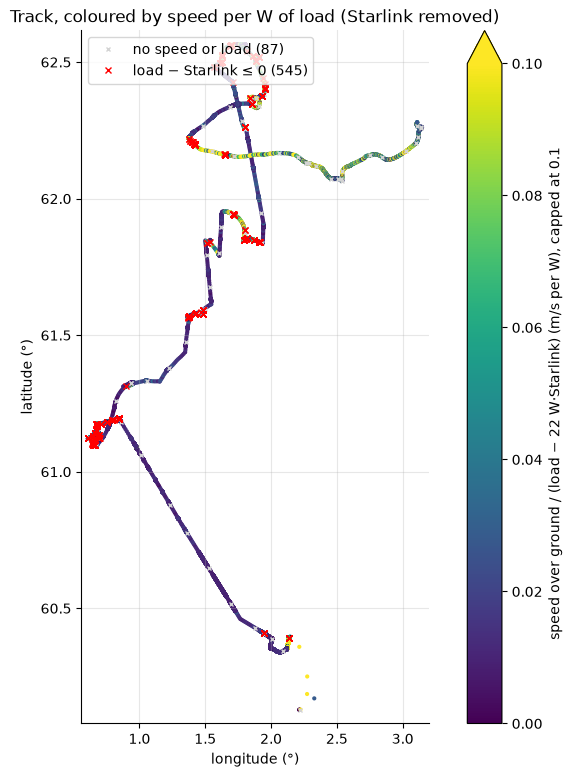

In [8]:
on_track = df[(df.latitude_deg != 0) & (df.longitude_deg != 0)]
map_pad = 0.05
fig, ax = plt.subplots(figsize=(10, 9))
none = df[df.speed_per_w.isna()]
ax.plot(none.longitude_deg, none.latitude_deg, "x", ms=3, color="lightgrey", label=f"no speed or load ({len(none)})")
ok = df[df.speed_per_w.notna() & (df.P_no_sl > 0)]          # already in time order
sc = ax.scatter(ok.longitude_deg, ok.latitude_deg, c=ok.speed_per_w, s=4, cmap="viridis", vmin=0, vmax=0.1)
low = df[df.speed_per_w.notna() & (df.P_no_sl <= 0)]
ax.plot(low.longitude_deg, low.latitude_deg, "x", ms=4, color="red", label=f"load − Starlink ≤ 0 ({len(low)})")
fig.colorbar(sc, ax=ax, label="speed over ground / (load − 22 W·Starlink) (m/s per W), capped at 0.1", extend="max")
ax.set_xlim(on_track.longitude_deg.min() - map_pad, on_track.longitude_deg.max() + map_pad)
ax.set_ylim(on_track.latitude_deg.min() - map_pad, on_track.latitude_deg.max() + map_pad)
ax.set_aspect(1 / np.cos(np.radians(on_track.latitude_deg.mean())))
ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)")
ax.set_title("Track, coloured by speed per W of load (Starlink removed)")
ax.legend(loc="upper left")
plt.show()

### Propulsion power vs speed over ground, everything merged except MANUAL

All minutes in one set except MANUAL (motor off, so its speed is drift): AUTO, mode 17 and minutes with no mode, Starlink off and on. Same per-minute data as the plots above, with propulsion = load − 10 − 22·Starlink. This is the point cloud to fit a model to.

Line = median per 0.2 m/s bin, band = middle 50%. Bins with fewer than 15 minutes are left out. Axes are cropped at 2.5 m/s and −30…170 W; the title counts the minutes that fall outside.

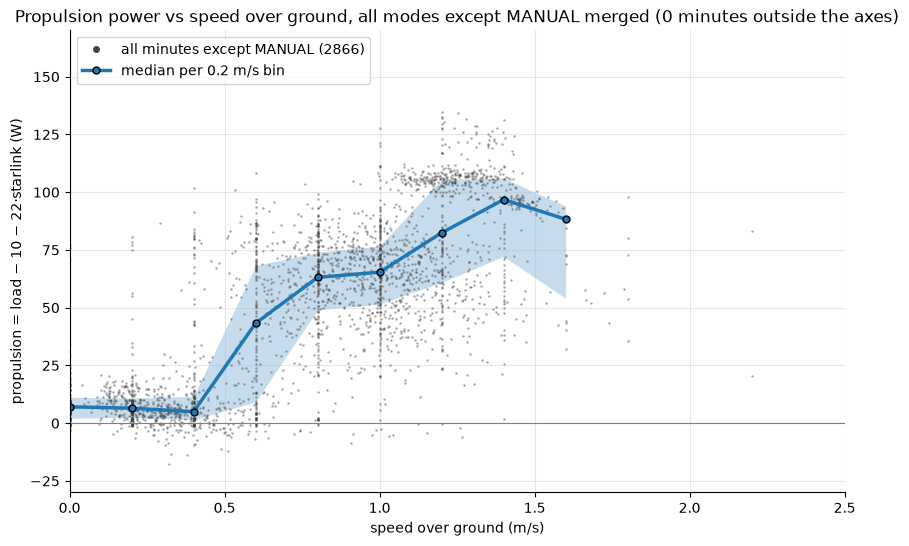

,q25,median,q75,n
x,,,,
0.0,2.2,7.1,11.2,105
0.2,2.5,6.5,10.9,400
0.4,1.5,5.0,11.6,341
0.6,9.2,43.3,68.3,296
0.8,49.1,63.1,74.0,415
1.0,51.6,65.4,76.8,564
1.2,61.0,82.4,105.6,461
1.4,72.1,96.8,106.1,244
1.6,54.0,88.3,94.0,30


In [9]:
XMAX, YMIN, YMAX = 2.5, -30, 170
all_min = m[m.custom_mode != 0].dropna(subset=["groundspeed_ms", "P_prop"])   # MANUAL out: motor off, speed is drift
out = ((all_min.groundspeed_ms > XMAX) | (all_min.P_prop < YMIN) | (all_min.P_prop > YMAX)).sum()
cv_all = curve(all_min)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(all_min.groundspeed_ms, all_min.P_prop, ".", ms=2, alpha=0.3, color="#444444")
ax.plot([], [], "o", ms=4, color="#444444", label=f"all minutes except MANUAL ({len(all_min)})")   # legend marker
ax.fill_between(cv_all.x, cv_all.q25, cv_all.q75, color="#1f77b4", alpha=0.25, lw=0)
ax.plot(cv_all.x, cv_all["median"], "-o", ms=5, lw=2.5, color="#1f77b4", mec="k", label="median per 0.2 m/s bin")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, XMAX); ax.set_ylim(YMIN, YMAX)
ax.set_xlabel("speed over ground (m/s)"); ax.set_ylabel("propulsion = load − 10 − 22·starlink (W)")
ax.set_title(f"Propulsion power vs speed over ground, all modes except MANUAL merged ({out} minutes outside the axes)")
ax.legend(loc="upper left")
plt.show()
cv_all.set_index("x").round(1)

# Part 2. Model

## 3. Model: propulsion = k · v³, with hotel and Starlink fixed

Hotel and Starlink come from the MANUAL estimates above (MANUAL ≈ motor off, because load stays flat with speed there): **hotel = 10 W, Starlink = 22 W**. Subtract them from the load and fit what's left:

**load − 10 − 22 · Starlink = k · v³**

There's no free intercept. The base load is already fixed by the MANUAL numbers, so the curve has to go through 0 W at 0 m/s.

- **Starlink** = 1 if the minute is inside a Starlink session (same flag as above).
- **v** = speed over ground (m/s), per-minute mean.

Same minutes as the merged plot (everything except MANUAL). Ordinary least squares with `np.linalg.lstsq`. R² is measured against the mean of the data, as usual, so it can be low or even negative when the curve has to pass through zero.

,value,std error
k (W per (m/s)³),39.32,0.52


hotel = 10 W and Starlink = 22 W fixed, no intercept; n = 2866 minutes, R² = 0.054, residual std = 32.2 W


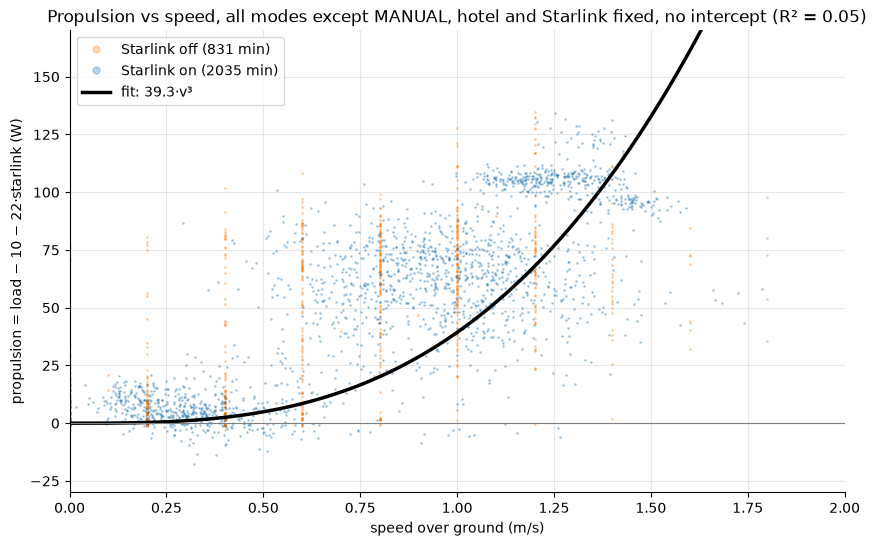

In [10]:
fit = m[m.custom_mode != 0].dropna(subset=["groundspeed_ms", "P_prop"])   # P_prop = load − HOTEL_W − STARLINK_W·starlink
X = (fit.groundspeed_ms ** 3).values[:, None]
y = fit.P_prop.values
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ coef
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (resid ** 2).sum() / (len(y) - X.shape[1]))
k = coef[0]
display(pd.DataFrame({"value": coef, "std error": se}, index=["k (W per (m/s)³)"]).round(2))
print(f"hotel = {HOTEL_W} W and Starlink = {STARLINK_W} W fixed, no intercept; "
      f"n = {len(y)} minutes, R² = {r2:.3f}, residual std = {resid.std():.1f} W")

fig, ax = plt.subplots(figsize=(10, 6))
for sl in [False, True]:
    s = fit[fit.starlink == sl]
    ax.plot(s.groundspeed_ms, s.P_prop, ".", ms=2, alpha=0.3, color=SL_COLORS[sl], label=f"{SL_NAMES[sl]} ({len(s)} min)")
v = np.linspace(0, 2, 200)
ax.plot(v, k * v ** 3, lw=2.5, color="k", label=f"fit: {k:.1f}·v³")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 2); ax.set_ylim(-30, 170)
ax.set_xlabel("speed over ground (m/s)"); ax.set_ylabel("propulsion = load − 10 − 22·starlink (W)")
ax.set_title(f"Propulsion vs speed, all modes except MANUAL, hotel and Starlink fixed, no intercept (R² = {r2:.2f})")
ax.legend(markerscale=5, loc="upper left")
plt.show()

### Final parameters

**load = P_hotel + P_starlink · Starlink + k · v³**

The table below is built from the variables above, so it updates if the notebook changes.

Things to know when you use it:
- **k is the weak part.** Load rises to about 60–80 W by 0.8 m/s and then flattens at about 105 W, while the cubic stays low there. Expect errors of about 30 W per minute at mid speeds.
- **About 105 W of propulsion around 1.2–1.5 m/s looks like a cap.** The model doesn't include it.
- **Some armed AUTO and mode-17 minutes have the motor basically off** (about 0 W below 0.5 m/s). The model treats them as normal minutes.
- **v is speed over ground,** so current and wind are mixed in.

In [11]:
pd.DataFrame([
    ["P_hotel", f"{HOTEL_W} W", "MANUAL, Starlink off: load flat with speed, so the motor is off",
     "moves between ~5 and 15 W over a day"],
    ["P_starlink", f"{STARLINK_W} W", "MANUAL, Starlink on minus off, the same at every speed",
     "anything that switches on with Starlink is counted in here"],
    ["k", f"{k:.1f} ± {se[0]:.1f} W/(m/s)³", f"least squares, {len(fit)} non-MANUAL minutes, no intercept",
     f"R² = {r2:.2f}, residual std ≈ {resid.std():.0f} W"],
    ["Starlink", "0 or 1", "1 inside a Starlink session (messages < 2 min apart, ± 30 s)", ""],
    ["v", "m/s", "per-minute mean speed over ground", "includes current and wind"],
], columns=["parameter", "value", "where it comes from", "how sure"]).set_index("parameter")

,value,where it comes from,how sure
parameter,,,
P_hotel,10 W,"MANUAL, Starlink off: load flat with speed, so...",moves between ~5 and 15 W over a day
P_starlink,22 W,"MANUAL, Starlink on minus off, the same at eve...",anything that switches on with Starlink is cou...
k,39.3 ± 0.5 W/(m/s)³,"least squares, 2866 non-MANUAL minutes, no int...","R² = 0.05, residual std ≈ 32 W"
Starlink,0 or 1,1 inside a Starlink session (messages < 2 min ...,
v,m/s,per-minute mean speed over ground,includes current and wind


## 3b. More models: k · v and k · v²

Same set-up as section 3 (hotel 10 W and Starlink 22 W fixed, same non-MANUAL minutes, no intercept), only the shape of the motor term changes:

| model | motor power | what it assumes |
| --- | --- | --- |
| **k·v** | grows in step with speed | the gentlest: about the same W per extra m/s at any speed |
| **k·v²** | grows with speed squared | in between |
| **k·v³** | grows with speed cubed (section 3) | textbook drag × speed, the steepest |

All three are 0 W at 0 m/s. The plot shows them over the same point cloud, with the median per 0.2 m/s bin from section 2 (blue) to judge which shape follows the data. The table gives each k, the fit quality, and what each model says the motor draws at 1.0 and 1.2 m/s.

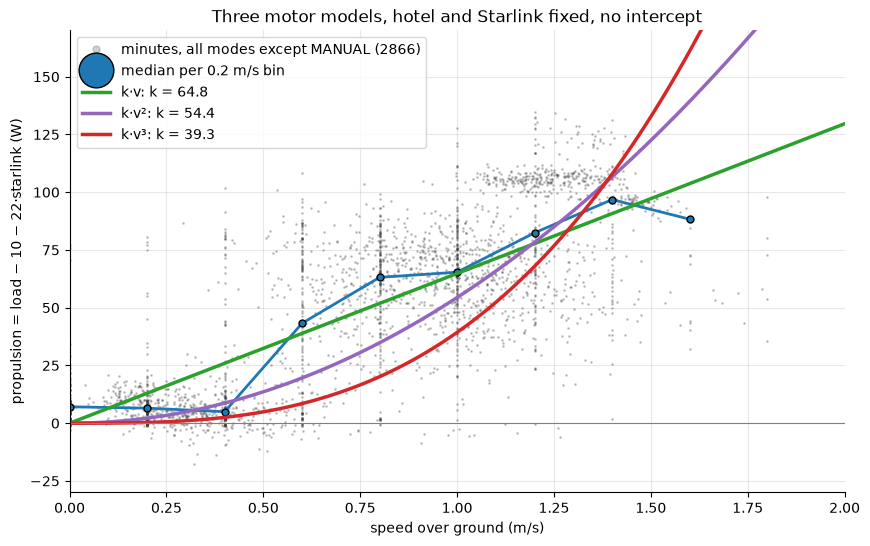

,k,std error,R²,residual std (W),median |residual| (W),motor at 1.0 m/s (W),motor at 1.2 m/s (W)
model,,,,,,,
k·v,64.81,0.51,0.58,23.99,16.54,64.81,77.78
k·v²,54.41,0.52,0.41,27.42,15.54,54.41,78.35
k·v³,39.32,0.52,0.05,32.18,19.36,39.32,67.94


In [12]:
MOTOR_MODELS = {}                       # name -> (power of v, k)
rows = []
for name, n in [("k·v", 1), ("k·v²", 2), ("k·v³", 3)]:
    Xn = (fit.groundspeed_ms ** n).values[:, None]
    cn, *_ = np.linalg.lstsq(Xn, y, rcond=None)
    rn = y - Xn @ cn
    sen = np.sqrt(np.linalg.inv(Xn.T @ Xn)[0, 0] * (rn ** 2).sum() / (len(y) - 1))
    MOTOR_MODELS[name] = (n, cn[0])
    rows.append({"model": name, "k": cn[0], "std error": sen,
                 "R²": 1 - (rn ** 2).sum() / ((y - y.mean()) ** 2).sum(), "residual std (W)": rn.std(),
                 "median |residual| (W)": np.median(np.abs(rn)),
                 "motor at 1.0 m/s (W)": cn[0], "motor at 1.2 m/s (W)": cn[0] * 1.2 ** n})
assert np.isclose(MOTOR_MODELS["k·v³"][1], k)          # same as section 3
MODEL_COLORS = {"k·v": "#2ca02c", "k·v²": "#9467bd", "k·v³": "#d62728"}

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(fit.groundspeed_ms, fit.P_prop, ".", ms=2, alpha=0.25, color="#444444", label=f"minutes, all modes except MANUAL ({len(fit)})")
ax.plot(cv_all.x, cv_all["median"], "-o", ms=5, lw=2, color="#1f77b4", mec="k", label="median per 0.2 m/s bin")
vv = np.linspace(0, 2, 200)
for name, (n, kn) in MOTOR_MODELS.items():
    ax.plot(vv, kn * vv ** n, lw=2.5, color=MODEL_COLORS[name], label=f"{name}: k = {kn:.1f}")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 2); ax.set_ylim(-30, 170)
ax.set_xlabel("speed over ground (m/s)"); ax.set_ylabel("propulsion = load − 10 − 22·starlink (W)")
ax.set_title("Three motor models, hotel and Starlink fixed, no intercept")
ax.legend(markerscale=5, loc="upper left")
plt.show()
pd.DataFrame(rows).set_index("model").round(2)

**What we see (three shapes):**
- **k·v follows the bin medians best** from 0.6 to 1.4 m/s (R² 0.58, against 0.41 for k·v² and 0.05 for k·v³). At 1 m/s it gives 65 W, close to the measured median of about 65 W; k·v³ gives only 39 W.
- **None of them has the right shape.** The data looks like a step, not a smooth curve: about 5 W below 0.5 m/s (motor basically off), a jump to 45–65 W at 0.6–0.8 m/s, then a flat top around 105 W from 1.2 m/s. k·v is too high at low speed, and k·v² and k·v³ are too low in the middle and shoot past the flat top.

# Part 3. Prediction

## 4. Prediction: load from speed and Starlink

Three inputs per minute go into the model: **speed over ground**, **Starlink on/off** and the **mode**:

**P_load_pred = 10 + 22 · Starlink + motor · k · v³**, with **motor = 0 in MANUAL** and 1 in AUTO / mode 17

and the result is compared with the measured load (battery1 V × battery2 A, per-minute mean). Every minute with a speed reading is used, **all modes, MANUAL included**. MANUAL uses the MANUAL load model (nb 06: motor off), so its prediction is just 10 + 22·Starlink and the drift speed is ignored. Error = actual − predicted.

The few speed outliers (up to 34 m/s on 14 Jul, see nb 01) are kept. Where they fall in a motor-on mode, v³ turns them into predictions of thousands of W, which blow up RMSE and max error, so the table also shows the **median |error|**, which they can't distort. The plots crop the axes and count the minutes outside.

In [13]:
p = m.dropna(subset=["groundspeed_ms"]).copy()
p["motor"] = (p.custom_mode != 0).astype(int)          # MANUAL = motor off (nb 06), AUTO / mode 17 = motor on
p["P_pred"] = HOTEL_W + STARLINK_W * p.starlink + p.motor * k * p.groundspeed_ms ** 3
p["err"] = p.P_load - p.P_pred
p["mode"] = p.custom_mode.map(MODE_NAMES).fillna("no mode")
p.loc[p.custom_mode == 0, "mode"] = np.where(p.loc[p.custom_mode == 0, "armed"], "MANUAL armed", "MANUAL disarmed")   # MANUAL split by arming

def scores(e):
    return pd.Series({"minutes": len(e), "mean error (W)": e.mean(), "RMSE (W)": np.sqrt((e ** 2).mean()), "median |error| (W)": e.abs().median(), "max |error| (W)": e.abs().max()})

by_mode = pd.concat([p.groupby("mode").err.apply(scores).unstack(), scores(p.err).to_frame("all").T])
by_mode.round(1)

,minutes,mean error (W),RMSE (W),median |error| (W),max |error| (W)
AUTO,1747.0,19.8,36.9,24.9,398.2
MANUAL armed,2403.0,1.4,10.1,3.3,97.0
MANUAL disarmed,630.0,0.2,5.8,2.5,80.1
mode 17,1119.0,9.6,34.2,9.5,335.6
all,5899.0,8.3,25.9,5.5,398.2


**Over the mission.** Top: measured load (grey dots, one per minute) and the prediction (red dots), with hourly means as lines so the trend shows through the noise. Bottom: error = actual − predicted, per minute.

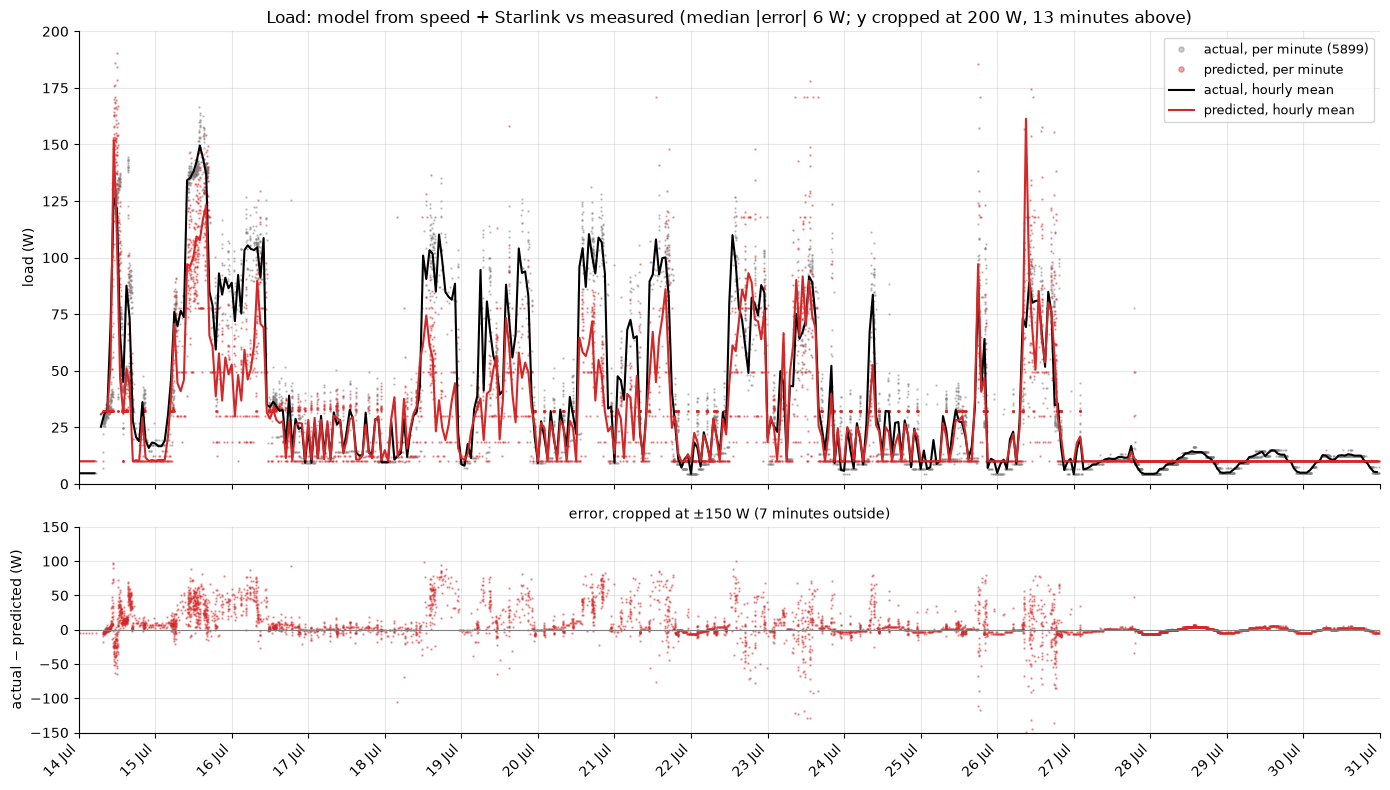

In [14]:
hourly = p.set_index("t")[["P_load", "P_pred"]].resample("1h").mean()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax.plot(p.t, p.P_load, ".", ms=1.5, alpha=0.4, color="grey", label=f"actual, per minute ({len(p)})")
ax.plot(p.t, p.P_pred, ".", ms=1.5, alpha=0.4, color="#d62728", label="predicted, per minute")
ax.plot(hourly.index, hourly.P_load, "-", lw=1.5, color="k", label="actual, hourly mean")
ax.plot(hourly.index, hourly.P_pred, "-", lw=1.5, color="#d62728", label="predicted, hourly mean")
ax.set_ylim(0, 200)
ax.set_ylabel("load (W)")
n_hi = (p[["P_load", "P_pred"]] > 200).any(axis=1).sum()
ax.set_title(f"Load: model from speed + Starlink vs measured (median |error| {p.err.abs().median():.0f} W; y cropped at 200 W, {n_hi} minutes above)")
ax.legend(markerscale=5, loc="upper right", fontsize=9)
ax2.plot(p.t, p.err, ".", ms=1.5, alpha=0.4, color="#d62728")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylim(-150, 150)
ax2.set_title(f"error, cropped at ±150 W ({(p.err.abs() > 150).sum()} minutes outside)", fontsize=10)
ax2.set_ylabel("actual − predicted (W)")
daily_axis(ax2)
plt.tight_layout(); plt.show()

**Per day:** mean measured vs mean predicted load over the minutes with data, and the error.

In [15]:
daily = p.groupby(p.t.dt.floor("D")).agg(minutes=("err", "size"), actual_W=("P_load", "mean"),
                                         predicted_W=("P_pred", "mean"), mean_error_W=("err", "mean"))
daily["RMSE_W"] = p.groupby(p.t.dt.floor("D")).err.apply(lambda e: np.sqrt((e ** 2).mean()))
daily.set_axis(daily.index.strftime("%d %b")).round(1).T

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
minutes,630.0,514.0,363.0,207.0,216.0,231.0,274.0,288.0,343.0,319.0,288.0,309.0,369.0,307.0,671.0,288.0,282.0
actual_W,65.6,106.6,60.5,24.9,68.0,59.3,65.7,51.0,45.2,50.3,30.4,35.2,53.1,8.9,10.0,10.4,10.0
predicted_W,55.2,81.0,42.1,24.6,41.9,41.7,41.5,38.0,41.4,50.4,24.2,33.3,55.4,11.0,10.0,10.0,10.0
mean_error_W,10.4,25.6,18.4,0.3,26.1,17.6,24.1,13.0,3.8,-0.1,6.1,1.9,-2.4,-2.1,-0.0,0.4,0.0
RMSE_W,25.1,32.3,29.4,5.9,42.4,30.7,34.8,28.6,26.2,38.2,17.2,26.6,36.5,5.4,3.5,3.4,3.0


### Closer look: four days, telemetry

Same four days as the plan grid in section 5 (change `DATES_TELEMETRY` to look at others), but for the **telemetry prediction**: inputs are the real speed over ground, whether Starlink was really on, and the mode (motor = 0 in MANUAL).
- **grey dots** = measured load; **red dots** = predicted from telemetry (10 + 22·Starlink + motor·k·v³, motor = 0 in MANUAL), both per minute with data, prediction cropped at 200 W
- **blue line, right axis** = speed over ground (what goes into k·v³)
- **orange bars at the top** = Starlink really on
- **coloured strip at the bottom** = the real mode (grey MANUAL, green AUTO, red mode 17)

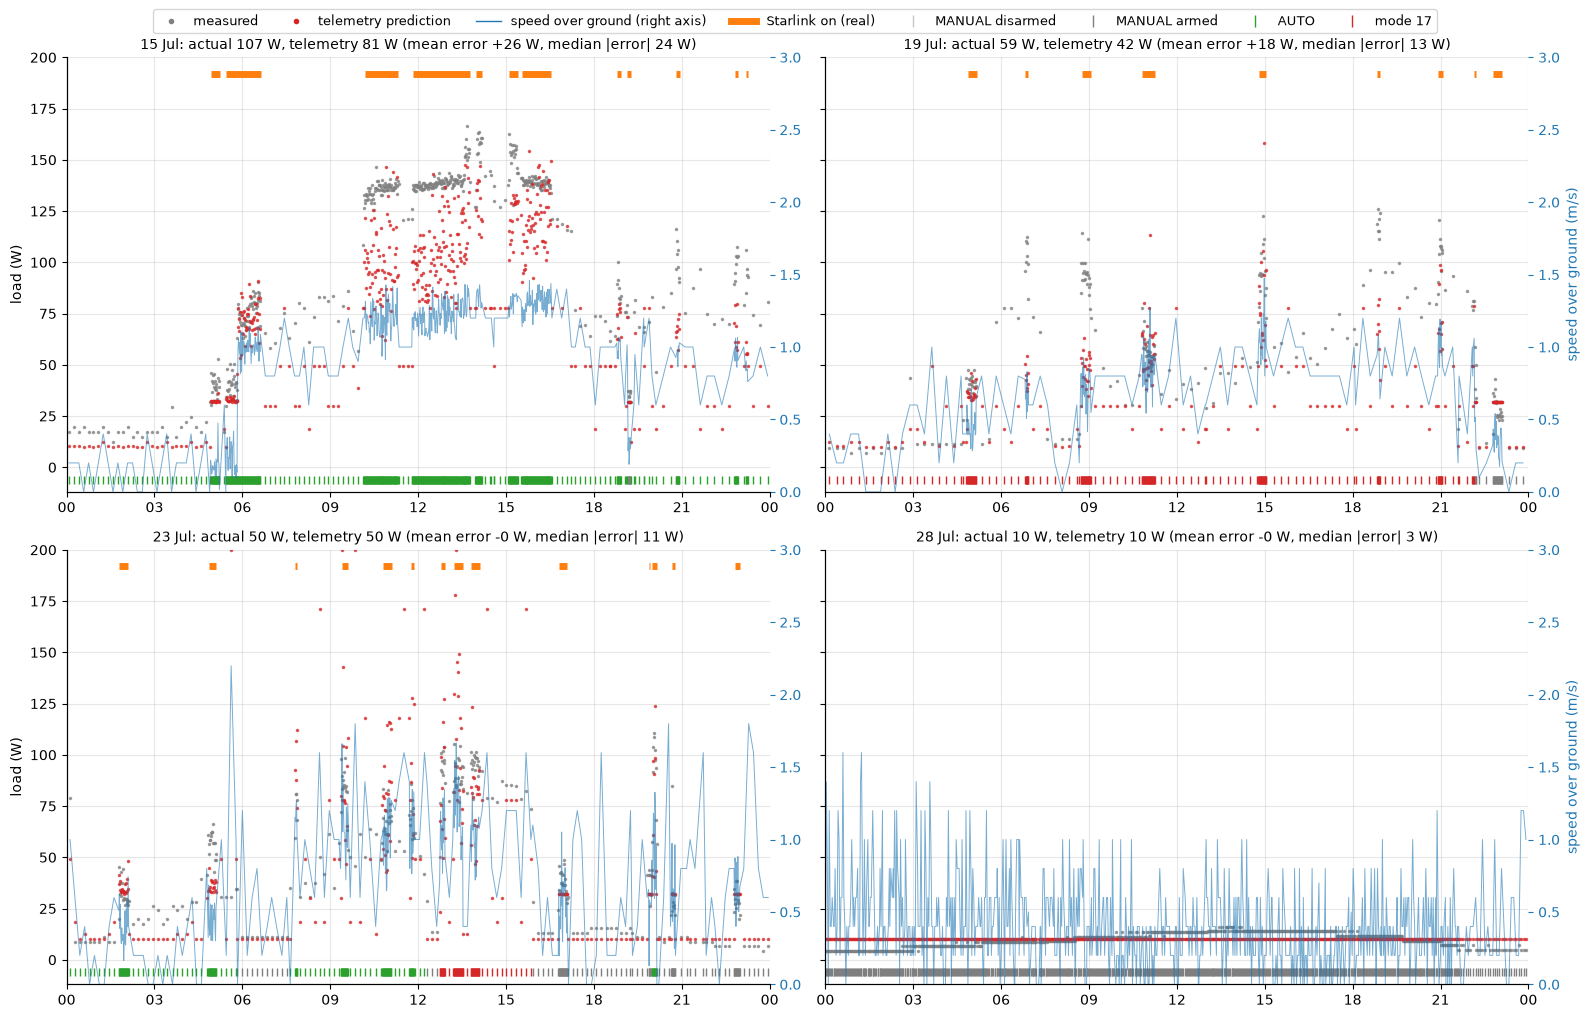

In [16]:
DATES_TELEMETRY = ["2025-07-15", "2025-07-19", "2025-07-23", "2025-07-28"]
MODE_STRIP = {-1: "#c7c7c7", 0: "#7f7f7f", 10: "#2ca02c", 17: "#d62728"}   # -1 = MANUAL disarmed

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for ax, day in zip(axes.flat, DATES_TELEMETRY):
    d0 = pd.Timestamp(day, tz="UTC"); d1 = d0 + pd.Timedelta("1D")
    q = p[(p.t >= d0) & (p.t < d1)]
    ax.plot(q.t, q.P_load, ".", ms=3, color="grey", alpha=0.7)
    ax.plot(q.t, q.P_pred.clip(upper=200), ".", ms=3, color="#d62728", alpha=0.7)
    for s in sessions[(sessions.end >= d0) & (sessions.start < d1)].itertuples():
        ax.plot([max(s.start, d0), min(s.end, d1)], [192, 192], color="#ff7f0e", lw=5, solid_capstyle="butt")
    qm = q.dropna(subset=["custom_mode"]).assign(ma=lambda x: np.where((x.custom_mode == 0) & ~x.armed, -1, x.custom_mode))
    for mode, g in qm.groupby("ma"):
        ax.plot(g.t, np.full(len(g), -6), "|", ms=6, color=MODE_STRIP.get(int(mode), "k"))
    ax2 = ax.twinx()
    ax2.plot(q.t, q.groundspeed_ms, "-", lw=0.7, color="#1f77b4", alpha=0.6)
    ax2.set_ylim(0, 3); ax2.grid(False)
    ax2.tick_params(axis="y", colors="#1f77b4")
    if ax in axes[:, 1]:
        ax2.set_ylabel("speed over ground (m/s)", color="#1f77b4")
    e = q.err
    ax.set_title(f"{d0:%d %b}: actual {q.P_load.mean():.0f} W, telemetry {q.P_pred.mean():.0f} W "
                 f"(mean error {e.mean():+.0f} W, median |error| {e.abs().median():.0f} W)", fontsize=10)
    ax.set_xlim(d0, d1); ax.set_ylim(-12, 200)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
for ax in axes[:, 0]:
    ax.set_ylabel("load (W)")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker=".", ls="", color="grey", label="measured"),
                    Line2D([], [], marker=".", ls="", color="#d62728", label="telemetry prediction"),
                    Line2D([], [], color="#1f77b4", lw=1, label="speed over ground (right axis)"),
                    Line2D([], [], color="#ff7f0e", lw=5, label="Starlink on (real)")]
           + [Line2D([], [], marker="|", ls="", ms=8, color=MODE_STRIP[k], label=n) for k, n in [(-1, "MANUAL disarmed"), (0, "MANUAL armed"), (10, "AUTO"), (17, "mode 17")]],
           loc="upper center", ncol=8, bbox_to_anchor=(0.5, 1.02), fontsize=9)
plt.tight_layout(); plt.show()

**What we see (telemetry, four days):**
- **28 Jul (MANUAL, motor off):** spot on at 10 W. MANUAL uses the motor-off model, so the drift speed no longer matters.
- **23 Jul (AUTO, mode 17 and MANUAL mixed):** right on average (50 vs 50 W). Speed over ground still jumps between 0 and 2 m/s from one reading to the next (Iridium speed comes in 0.1 m/s steps, plus current and waves), and v³ blows every jump up, so per minute it scatters a lot while the motor is on.
- **15 Jul (AUTO transit):** right shape but too low: about 85–120 W predicted at 1.1–1.3 m/s with Starlink on, against 135–150 W measured (day mean 81 vs 107 W). k·v³ is too small at cruise speed.
- **19 Jul (mode 17):** too low (42 vs 59 W). The motor bursts during Starlink sessions draw 100–125 W and the model misses them.

## 5. Prediction from the plan

Section 4 uses telemetry as its inputs: the measured speed and whether Starlink was really on. Here the inputs come only from the **plan** reverse-engineered in nb 05/04 (`data/mission_starlink.csv`, `data/mission_waypoints.csv`), the same plan the forecast in nb 12 uses:

- **Starlink:** every session nb 05 found (scheduled, extra and deployment), each an on-window from its first to its last Starlink message ± 30 s. Per minute, Starlink = the share of that minute inside a window.
- **Motor:** each of the 12 runs departs at its time and runs at **1 m/s** for (run length) / 3.6 h. Otherwise v = 0, so drifting in MANUAL adds nothing.

Same model: **P_load_plan = 10 + 22 · Starlink_plan + k · v_plan³**, so 10 W waiting and 49 W under way (plus 22 W with Starlink on). Compared on the same minutes as section 4. Error = actual − predicted.

In [17]:
sl_plan = pd.read_csv("../data/mission_starlink.csv", parse_dates=["from", "to"]).rename(columns={"from": "start"})   # one row per session (nb 05)
wps = pd.read_csv("../data/mission_waypoints.csv", parse_dates=["depart"])
runs = wps.assign(run=wps.depart.notna().cumsum()).groupby("run").agg(depart=("depart", "first"), km=("km", "sum"))
runs["end"] = runs.depart + pd.to_timedelta(runs.km * 1000 / 1.0, unit="s")

def plan_inputs(ts):
    """Starlink share (0-1) and speed (m/s) at times ts, from the plan only."""
    ts = pd.DatetimeIndex(ts)
    sl = np.zeros(len(ts))
    for r in sl_plan.itertuples():   # share of each minute [t, t + 1 min) inside a session window
        sl += np.clip((np.minimum(ts + pd.Timedelta("1min"), r.to) - np.maximum(ts, r.start)).total_seconds() / 60, 0, 1)
    v = np.zeros(len(ts))
    for r in runs.itertuples():
        v[(ts >= r.depart) & (ts < r.end)] = 1.0
    return sl, v

p["sl_plan"], p["v_plan"] = plan_inputs(p.t)
p["P_plan"] = HOTEL_W + STARLINK_W * p.sl_plan + k * p.v_plan ** 3
p["err_plan"] = p.P_load - p.P_plan

comp = pd.concat({"telemetry (section 4)": pd.concat([p.groupby("mode").err.apply(scores).unstack(), scores(p.err).to_frame("all").T]),
                  "plan": pd.concat([p.groupby("mode").err_plan.apply(scores).unstack(), scores(p.err_plan).to_frame("all").T])})
print("plan vs reality, per minute:",
      f"Starlink on: plan {(p.sl_plan >= 1).mean():.0%} of minutes, real {p.starlink.mean():.0%};",
      f"motor on: plan {(p.v_plan > 0).mean():.0%}, real AUTO/mode 17 {(p.custom_mode.isin([10, 17])).mean():.0%}")
comp.round(1)

plan vs reality, per minute: Starlink on: plan 47% of minutes, real 49%; motor on: plan 27%, real AUTO/mode 17 49%


minutes  mean error (W)  RMSE (W)  \
telemetry (section 4) AUTO              1747.0            19.8      36.9   
                      MANUAL armed      2403.0             1.4      10.1   
                      MANUAL disarmed    630.0             0.2       5.8   
                      mode 17           1119.0             9.6      34.2   
                      all               5899.0             8.3      25.9   
plan                  AUTO              1747.0            36.5      45.0   
                      MANUAL armed      2403.0             1.1       9.6   
                      MANUAL disarmed    630.0             0.2       5.8   
                      mode 17           1119.0            17.3      29.6   
                      all               5899.0            14.6      28.4   

                                       median |error| (W)  max |error| (W)  
telemetry (section 4) AUTO                           24.9            398.2  
                      MANUAL armed                    3.3             97.0  
                      MANUAL disarmed                 2.5             80.1  
                      mode 17                         9.5            335.6  
                      all                             5.5            398.2  
plan                  AUTO                           35.1            105.3  
                      MANUAL armed                    3.4            100.3  
                      MANUAL disarmed                 2.5             80.1  
                      mode 17                        14.8            102.0  
                      all                             5.6            105.3

**Over the mission.** Hourly means of the measured load (black), the telemetry prediction from section 4 (grey) and the plan prediction (red). Blue shading = motor on in the plan. Bottom: hourly mean error of the plan prediction.

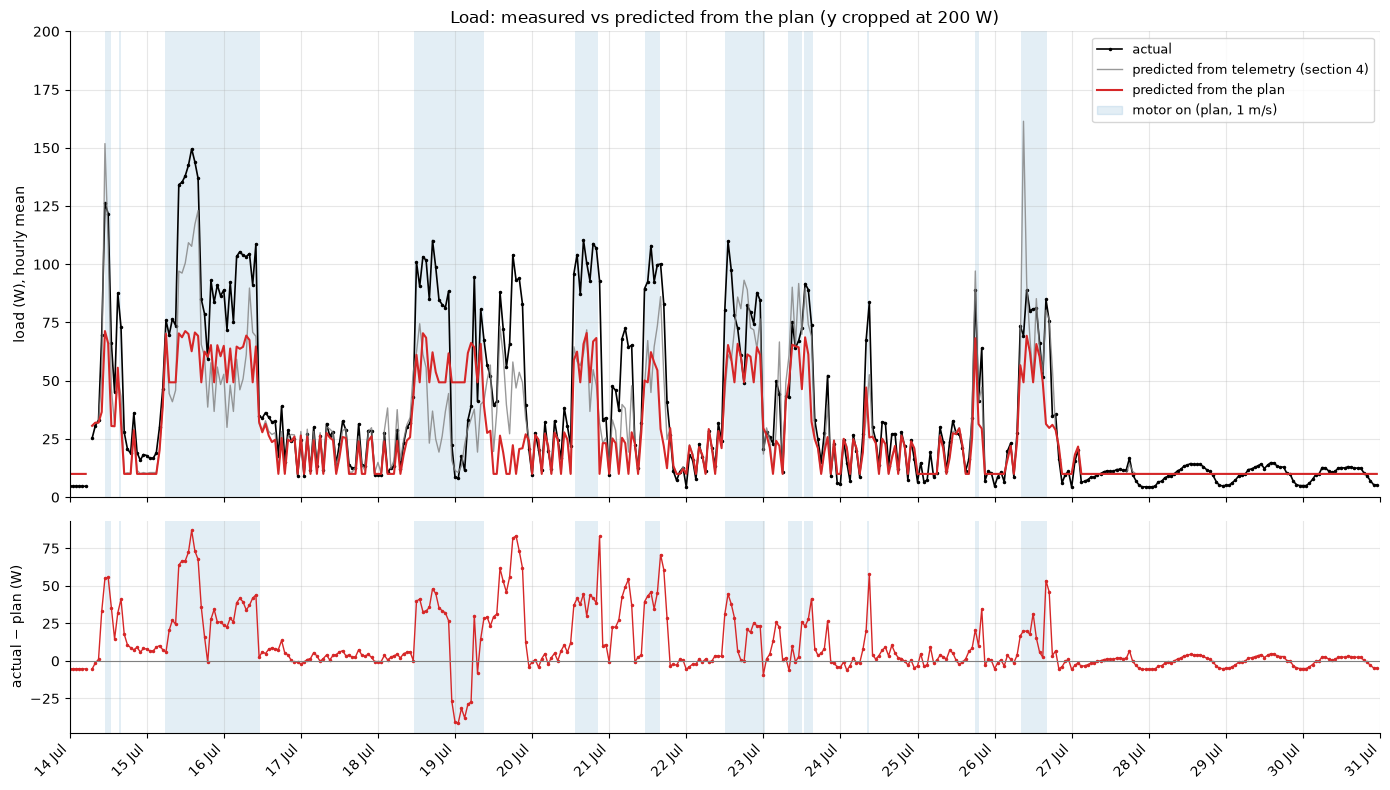

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
minutes,630.0,514.0,363.0,207.0,216.0,231.0,274.0,288.0,343.0,319.0,288.0,309.0,369.0,307.0,671.0,288.0,282.0
actual_W,65.6,106.6,60.5,24.9,68.0,59.3,65.7,51.0,45.2,50.3,30.4,35.2,53.1,8.9,10.0,10.4,10.0
telemetry_W,55.2,81.0,42.1,24.6,41.9,41.7,41.5,38.0,41.4,50.4,24.2,33.3,55.4,11.0,10.0,10.0,10.0
plan_W,39.7,61.0,42.8,21.9,46.5,36.7,43.8,25.7,36.5,38.7,23.2,27.0,38.8,10.7,10.0,10.0,10.0
plan error (W),25.9,45.6,17.7,3.0,21.5,22.6,21.8,25.3,8.7,11.7,7.1,8.2,14.2,-1.7,-0.0,0.4,0.0


In [18]:
h = p.set_index("t")[["P_load", "P_pred", "P_plan", "err_plan"]].resample("1h").mean()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for r in runs.itertuples():
    for a in (ax, ax2):
        a.axvspan(r.depart, r.end, color="#1f77b4", alpha=0.12, lw=0)
ax.plot(h.index, h.P_load, ".-", ms=3, lw=1.2, color="k", label="actual")
ax.plot(h.index, h.P_pred, "-", lw=1, color="grey", alpha=0.8, label="predicted from telemetry (section 4)")
ax.plot(h.index, h.P_plan, "-", lw=1.5, color="#d62728", label="predicted from the plan")
ax.set_ylim(0, 200); ax.set_ylabel("load (W), hourly mean")
ax.set_title("Load: measured vs predicted from the plan (y cropped at 200 W)")
from matplotlib.patches import Patch
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + [Patch(color="#1f77b4", alpha=0.12, label="motor on (plan, 1 m/s)")], loc="upper right", fontsize=9)
ax2.plot(h.index, h.err_plan, ".-", ms=3, lw=1, color="#d62728")
ax2.axhline(0, color="grey", lw=0.8)
ax2.set_ylabel("actual − plan (W)")
daily_axis(ax2)
plt.tight_layout(); plt.show()

d = p.groupby(p.t.dt.floor("D")).agg(minutes=("err", "size"), actual_W=("P_load", "mean"),
                                     telemetry_W=("P_pred", "mean"), plan_W=("P_plan", "mean"))
d["plan error (W)"] = d.actual_W - d.plan_W
d.set_axis(d.index.strftime("%d %b")).round(1).T

### Closer look: four days

Change `DATES` to look at other days. Each panel is one UTC day, minute by minute:
- **grey dots** = measured load
- **red line** = predicted from the plan (on a full minute grid, so it also shows where there's no data)
- **thin grey line** = predicted from telemetry (section 4), on the minutes with data
- **blue shading** = motor on in the plan (1 m/s); **orange ticks at the top** = Starlink really on; **red ticks just below** = Starlink on in the plan
- **coloured strip at the bottom** = the real mode (grey MANUAL, green AUTO, red mode 17)

Default days: **15 Jul** (long AUTO transit, the plan's worst day), **19 Jul** (mode-17 heading legs; the plan's 1 m/s finishes early), **23 Jul** (AUTO, mode 17 and MANUAL mixed), **28 Jul** (MANUAL, Starlink off: the 10 W baseline).

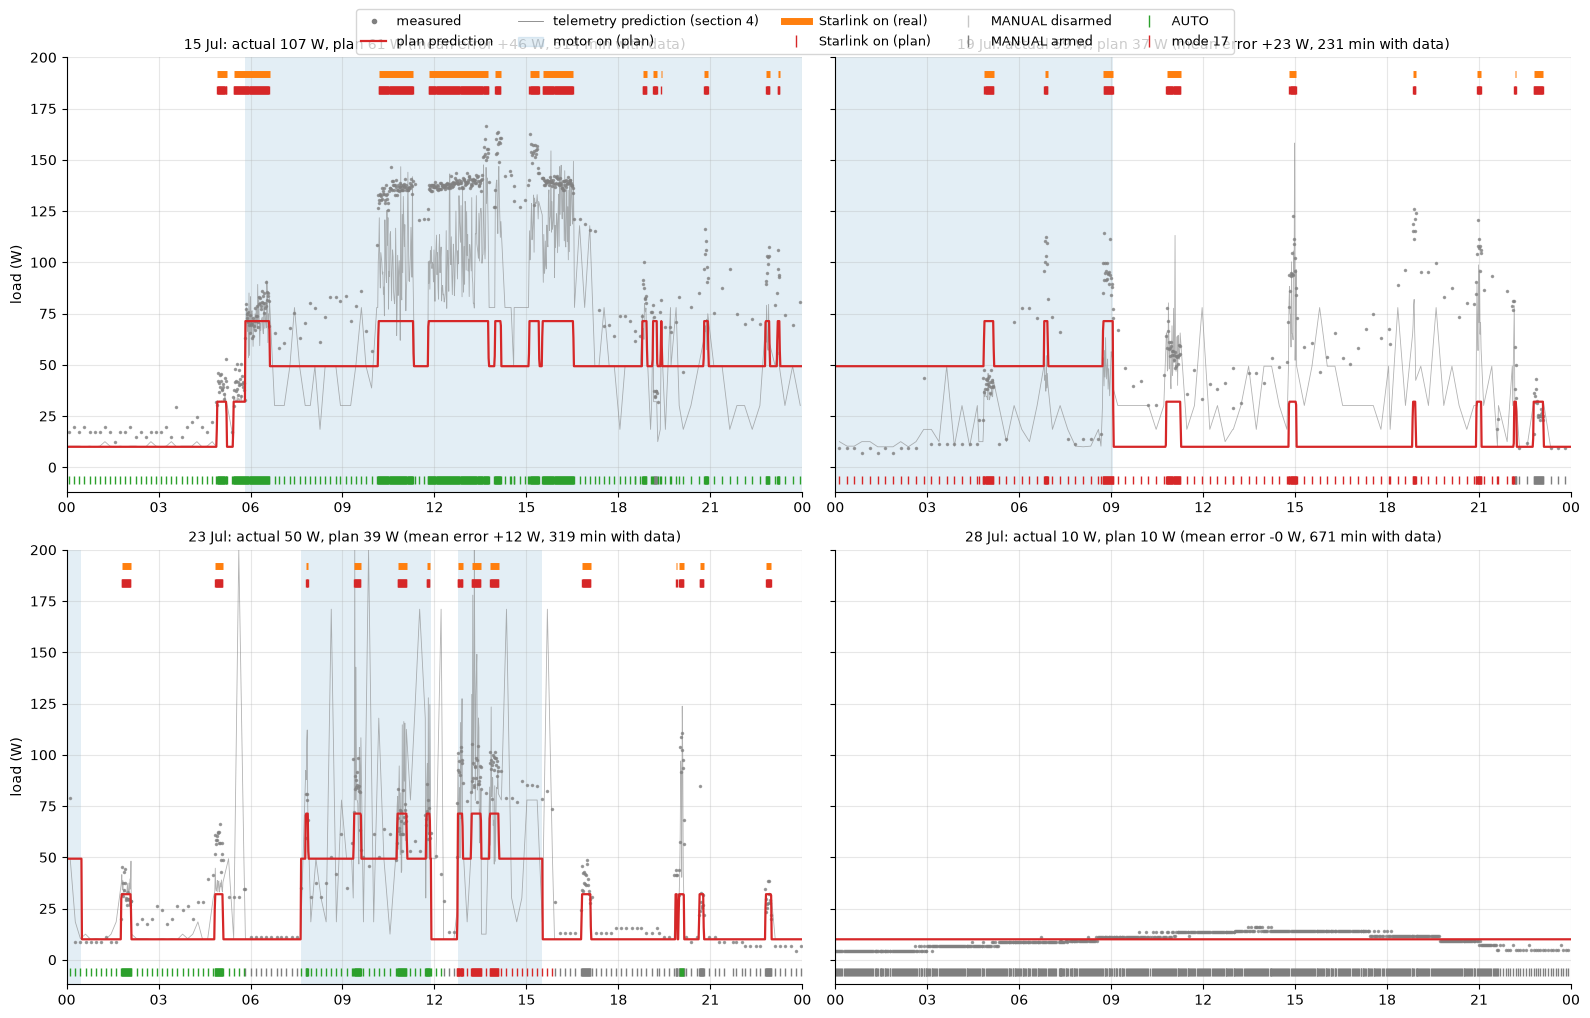

In [19]:
DATES = ["2025-07-15", "2025-07-19", "2025-07-23", "2025-07-28"]
MODE_STRIP = {-1: "#c7c7c7", 0: "#7f7f7f", 10: "#2ca02c", 17: "#d62728"}   # -1 = MANUAL disarmed

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for ax, day in zip(axes.flat, DATES):
    d0 = pd.Timestamp(day, tz="UTC"); d1 = d0 + pd.Timedelta("1D")
    grid = pd.date_range(d0, d1, freq="1min", inclusive="left")
    sl_g, v_g = plan_inputs(grid)
    plan_g = HOTEL_W + STARLINK_W * sl_g + k * v_g ** 3
    q = p[(p.t >= d0) & (p.t < d1)]
    on = (v_g > 0).astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(grid[a], grid[b - 1], color="#1f77b4", alpha=0.12, lw=0)
    ax.plot(q.t, q.P_load, ".", ms=3, color="grey", alpha=0.7)
    ax.plot(q.t, q.P_pred.clip(upper=200), "-", lw=0.6, color="grey", alpha=0.6)
    ax.plot(grid, plan_g, "-", lw=1.6, color="#d62728")
    for s in sessions[(sessions.end >= d0) & (sessions.start < d1)].itertuples():
        ax.plot([max(s.start, d0), min(s.end, d1)], [192, 192], color="#ff7f0e", lw=5, solid_capstyle="butt")
    sl_on = grid[sl_g >= 1]
    ax.plot(sl_on, np.full(len(sl_on), 184), "|", ms=6, color="#d62728")
    qm = q.dropna(subset=["custom_mode"]).assign(ma=lambda x: np.where((x.custom_mode == 0) & ~x.armed, -1, x.custom_mode))
    for mode, g in qm.groupby("ma"):
        ax.plot(g.t, np.full(len(g), -6), "|", ms=6, color=MODE_STRIP.get(int(mode), "k"))
    e = q.err_plan
    ax.set_title(f"{d0:%d %b}: actual {q.P_load.mean():.0f} W, plan {q.P_plan.mean():.0f} W "
                 f"(mean error {e.mean():+.0f} W, {len(q)} min with data)", fontsize=10)
    ax.set_xlim(d0, d1); ax.set_ylim(-12, 200)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
for ax in axes[:, 0]:
    ax.set_ylabel("load (W)")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker=".", ls="", color="grey", label="measured"),
                    Line2D([], [], color="#d62728", lw=1.6, label="plan prediction"),
                    Line2D([], [], color="grey", lw=0.6, label="telemetry prediction (section 4)"),
                    Patch(color="#1f77b4", alpha=0.12, label="motor on (plan)"),
                    Line2D([], [], color="#ff7f0e", lw=5, label="Starlink on (real)"),
                    Line2D([], [], marker="|", ls="", ms=8, color="#d62728", label="Starlink on (plan)")]
           + [Line2D([], [], marker="|", ls="", ms=8, color=MODE_STRIP[k], label=n) for k, n in [(-1, "MANUAL disarmed"), (0, "MANUAL armed"), (10, "AUTO"), (17, "mode 17")]],
           loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=9)
plt.tight_layout(); plt.show()

**What we see (plan prediction):**
- **Motor off is right in both.** MANUAL median |error| is 3.6 W for the plan and 3.3 W for telemetry; 28 Jul is spot on at 10 W in both. The real hotel load wobbles between about 5 and 15 W over the day.
- **The plan is worse than telemetry when the motor is on.** AUTO mean error +45 W (telemetry +20 W), mode 17 +27 W (telemetry +10 W). The plan's 49 W at 1 m/s is far below what the boat drew: about 135–150 W on 15 Jul (AUTO with Starlink), 60–100 W on 23 Jul. k·v³ at 1 m/s (39 W) is too small for the motor.
- **Timing slips where the boat was slower than 1 m/s.** On 19 Jul the plan finishes the mode-17 run at 09:00, but the real boat kept going until about 22:00, so the plan has the motor on when it was mostly idle and off when it was running.
- **Careful with the per-minute scores:** minutes with data are 49% Starlink-on (Starlink sends far more often), but the plan has Starlink on in only 14% of minutes. So these minutes over-represent Starlink time and make the plan look worse on Starlink than it is over the whole day (nb 12: 0.8 kWh planned vs about 1.0 kWh real).

## 6. Predictions with each motor model

The same two predictions as sections 4 and 5, run once per motor model:
- **from telemetry:** load = 10 + 22·Starlink (real) + motor · k·vⁿ with v = real speed over ground, motor = 0 in MANUAL
- **from the plan:** load = 10 + 22·Starlink (plan, nb 05) + k·vⁿ with v = 1 m/s on the plan's runs, else 0

With the plan, v is always 0 or 1, and 1ⁿ = 1, so the three models differ only by their k (the motor power at 1 m/s). With telemetry the shape matters too, because the real speed varies.

The table scores every combination by mode. Error = actual − predicted.

In [20]:
score_rows = {}
for name, (n, kn) in MOTOR_MODELS.items():
    p[f"tel {name}"] = HOTEL_W + STARLINK_W * p.starlink + p.motor * kn * p.groundspeed_ms ** n
    p[f"plan {name}"] = HOTEL_W + STARLINK_W * p.sl_plan + kn * p.v_plan ** n
    for src in ["tel", "plan"]:
        e = p.P_load - p[f"{src} {name}"]
        by = pd.concat([e.groupby(p["mode"]).apply(scores).unstack(), scores(e).to_frame("all").T])
        score_rows[("telemetry" if src == "tel" else "plan", name)] = by
sc = pd.concat(score_rows, names=["inputs", "model", "mode"])
sc[["mean error (W)", "median |error| (W)", "RMSE (W)", "max |error| (W)"]].unstack("mode").round(1)

mean error (W)                                             \
mode                      AUTO MANUAL armed MANUAL disarmed mode 17   all   
inputs    model                                                             
plan      k·v             20.4          0.9             0.2     7.1   7.8   
          k·v²            27.0          1.0             0.2    11.3  10.5   
          k·v³            36.5          1.1             0.2    17.3  14.6   
telemetry k·v              4.9          1.4             0.2    -9.3   0.3   
          k·v²            11.1          1.4             0.2     1.8   4.2   
          k·v³            19.8          1.4             0.2     9.6   8.3   

                median |error| (W)                                            \
mode                          AUTO MANUAL armed MANUAL disarmed mode 17  all   
inputs    model                                                                
plan      k·v                 19.8          3.4             2.5     7.1  5.3   
          k·v²                23.2          3.4             2.5     8.8  5.5   
          k·v³                35.1          3.4             2.5    14.8  5.6   
telemetry k·v                 16.2          3.3             2.5    17.1  5.5   
          k·v²                18.5          3.3             2.5    10.1  5.4   
          k·v³                24.9          3.3             2.5     9.5  5.5   

                RMSE (W)                                             \
mode                AUTO MANUAL armed MANUAL disarmed mode 17   all   
inputs    model                                                       
plan      k·v       33.3         10.0             5.8    27.5  22.7   
          k·v²      37.2          9.8             5.8    27.3  24.3   
          k·v³      45.0          9.6             5.8    29.6  28.4   
telemetry k·v       23.8         10.1             5.8    24.3  18.0   
          k·v²      28.9         10.1             5.8    27.6  20.9   
          k·v³      36.9         10.1             5.8    34.2  25.9   

                max |error| (W)                                              
mode                       AUTO MANUAL armed MANUAL disarmed mode 17    all  
inputs    model                                                              
plan      k·v             105.3        100.3            80.1   102.0  105.3  
          k·v²            105.3        100.3            80.1   102.0  105.3  
          k·v³            105.3        100.3            80.1   102.0  105.3  
telemetry k·v             122.2         97.0            80.1    88.8  122.2  
          k·v²            242.9         97.0            80.1   180.3  242.9  
          k·v³            398.2         97.0            80.1   335.6  398.2

**Over the mission.** Hourly means of the measured load (black) and of each model's prediction. Top: from telemetry. Bottom: from the plan (blue shading = motor on in the plan). Both cropped at 200 W.

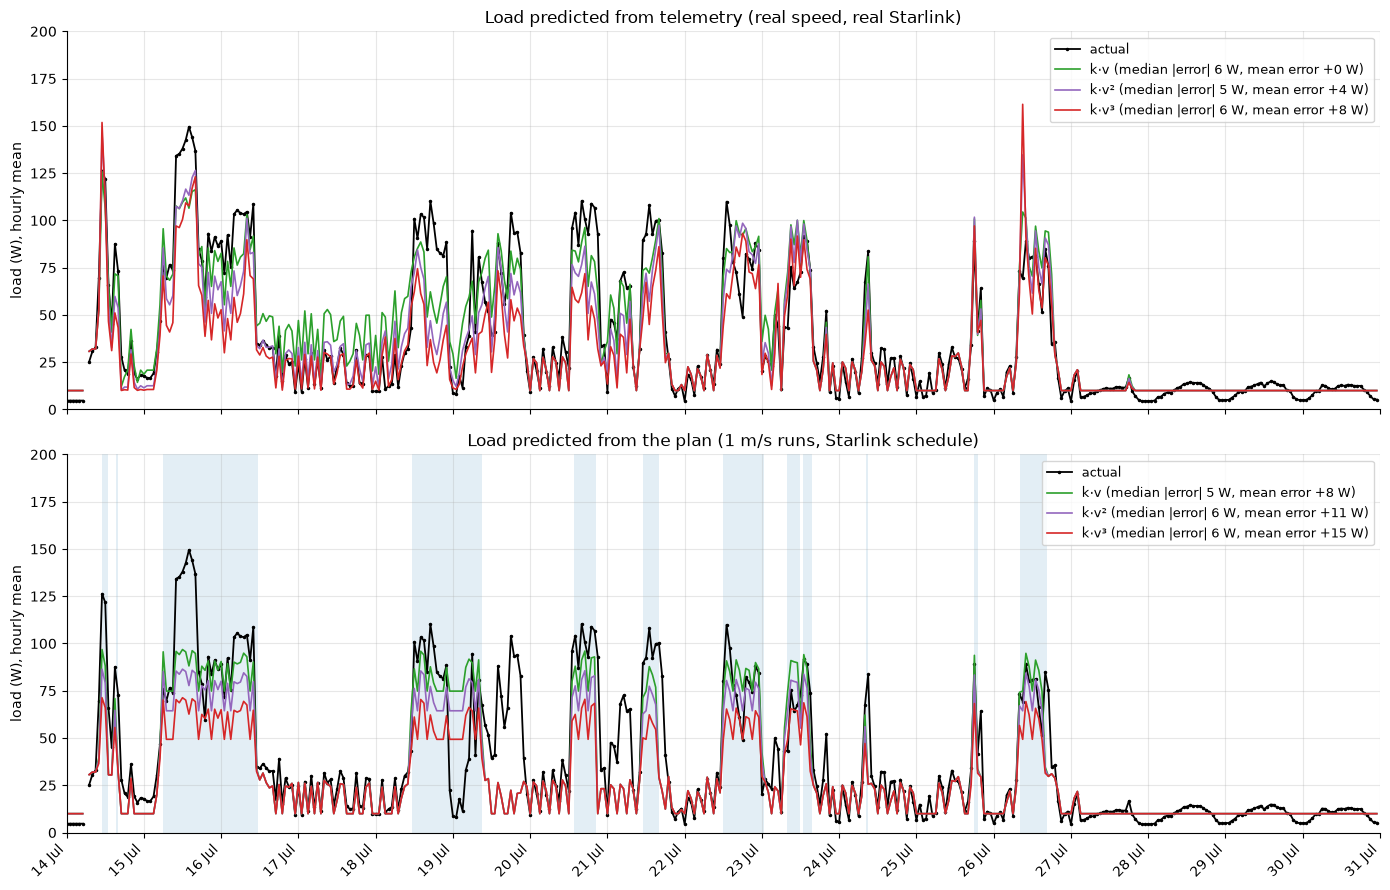

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
actual,66.0,107.0,60.0,25.0,68.0,59.0,66.0,51.0,45.0,50.0,30.0,35.0,53.0,9.0,10.0,10.0,10.0
tel k·v,61.0,92.0,62.0,44.0,66.0,64.0,55.0,49.0,48.0,59.0,28.0,35.0,63.0,11.0,10.0,10.0,10.0
tel k·v²,58.0,90.0,50.0,30.0,52.0,52.0,49.0,43.0,46.0,55.0,26.0,35.0,61.0,11.0,10.0,10.0,10.0
tel k·v³,55.0,81.0,42.0,25.0,42.0,42.0,42.0,38.0,41.0,50.0,24.0,33.0,55.0,11.0,10.0,10.0,10.0
plan k·v,46.0,83.0,54.0,22.0,62.0,46.0,56.0,28.0,47.0,49.0,24.0,30.0,48.0,11.0,10.0,10.0,10.0
plan k·v²,43.0,74.0,49.0,22.0,56.0,42.0,51.0,27.0,42.0,45.0,24.0,29.0,44.0,11.0,10.0,10.0,10.0
plan k·v³,40.0,61.0,43.0,22.0,46.0,37.0,44.0,26.0,36.0,39.0,23.0,27.0,39.0,11.0,10.0,10.0,10.0


In [21]:
hh = p.set_index("t")[["P_load"] + [f"{s} {n}" for s in ["tel", "plan"] for n in MOTOR_MODELS]].resample("1h").mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, src, title in zip(axes, ["tel", "plan"], ["from telemetry (real speed, real Starlink)", "from the plan (1 m/s runs, Starlink schedule)"]):
    if src == "plan":
        for r in runs.itertuples():
            ax.axvspan(r.depart, r.end, color="#1f77b4", alpha=0.12, lw=0)
    ax.plot(hh.index, hh.P_load, ".-", ms=3, lw=1.3, color="k", label="actual")
    for name in MOTOR_MODELS:
        e = p.P_load - p[f"{src} {name}"]
        ax.plot(hh.index, hh[f"{src} {name}"], "-", lw=1.2, color=MODEL_COLORS[name],
                label=f"{name} (median |error| {e.abs().median():.0f} W, mean error {e.mean():+.0f} W)")
    ax.set_ylim(0, 200); ax.set_ylabel("load (W), hourly mean")
    ax.set_title(f"Load predicted {title}")
    ax.legend(loc="upper right", fontsize=9)
daily_axis(axes[1])
plt.tight_layout(); plt.show()

dd = p.groupby(p.t.dt.floor("D"))[["P_load"] + [f"{s} {n}" for s in ["tel", "plan"] for n in MOTOR_MODELS]].mean()
dd.set_axis(dd.index.strftime("%d %b")).rename(columns={"P_load": "actual"}).round(0).T

**Four days, closer.** Same days as the grids above (`DATES`). Grey dots = measured load per minute. Solid lines = plan prediction per model (full minute grid). Dashed lines = telemetry prediction per model, smoothed with a 15-min rolling mean so the three can be told apart. Blue shading = motor on in the plan.

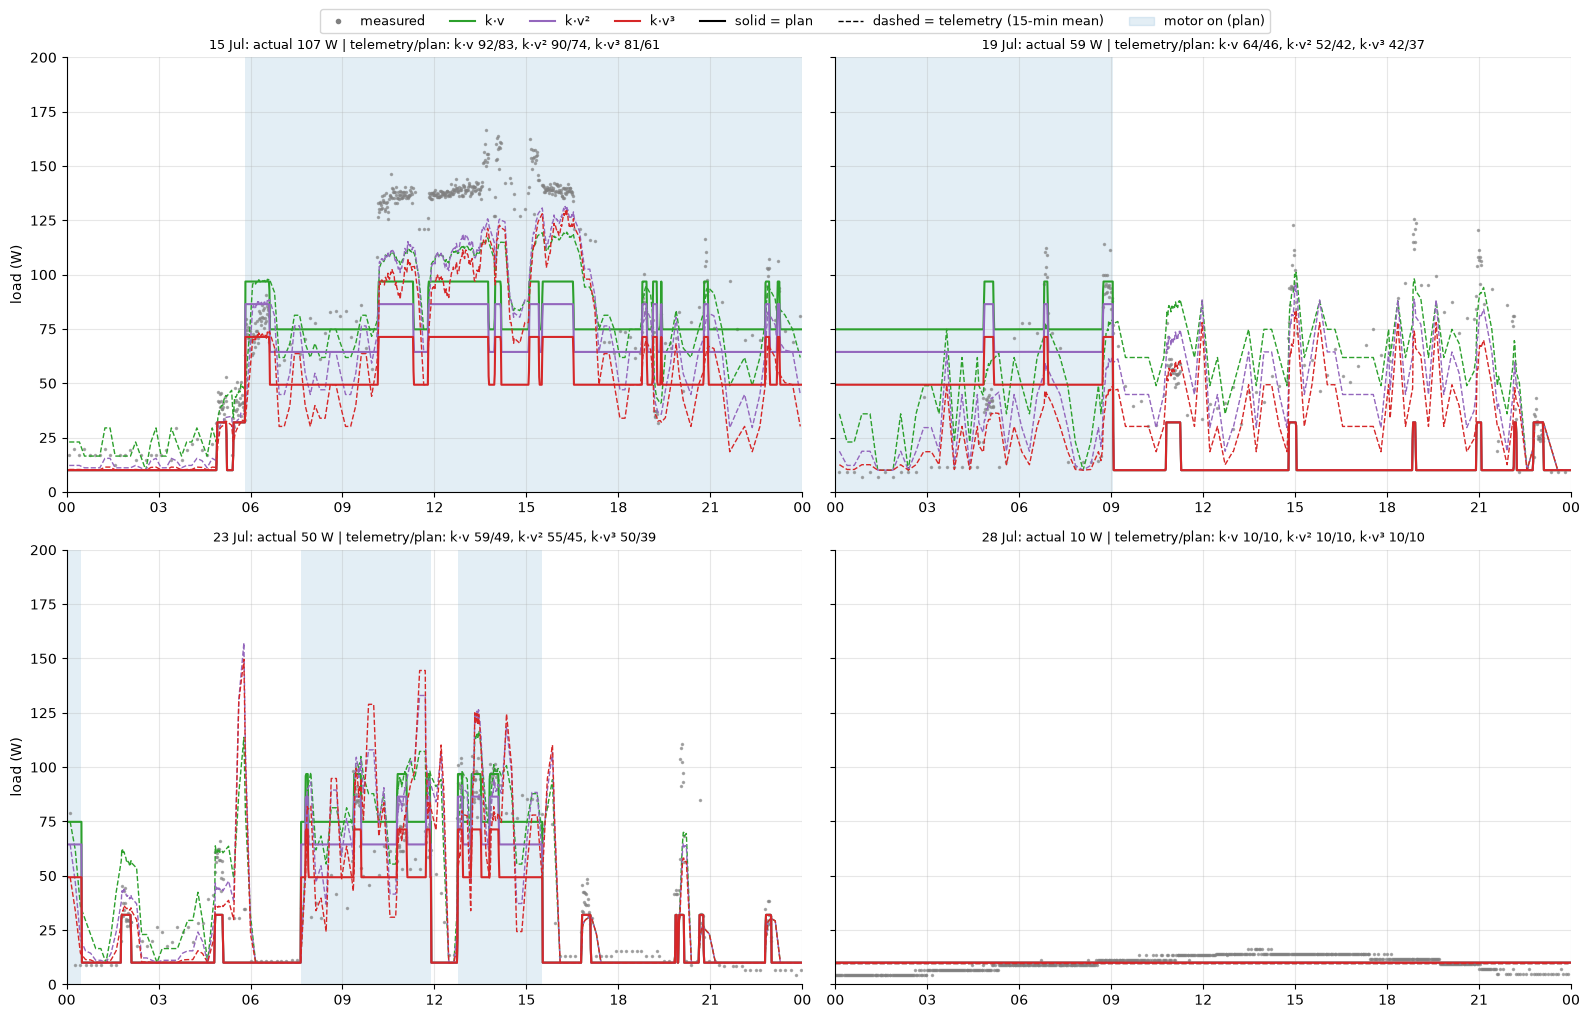

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for ax, day in zip(axes.flat, DATES):
    d0 = pd.Timestamp(day, tz="UTC"); d1 = d0 + pd.Timedelta("1D")
    grid = pd.date_range(d0, d1, freq="1min", inclusive="left")
    sl_g, v_g = plan_inputs(grid)
    q = p[(p.t >= d0) & (p.t < d1)].set_index("t")
    on = (v_g > 0).astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, on, 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(grid[a], grid[b - 1], color="#1f77b4", alpha=0.12, lw=0)
    ax.plot(q.index, q.P_load, ".", ms=3, color="grey", alpha=0.6)
    parts = []
    for name, (n, kn) in MOTOR_MODELS.items():
        ax.plot(grid, HOTEL_W + STARLINK_W * sl_g + kn * v_g ** n, "-", lw=1.5, color=MODEL_COLORS[name])
        tel = q[f"tel {name}"].clip(upper=250).rolling("15min").mean()
        ax.plot(tel.index, tel, "--", lw=1, color=MODEL_COLORS[name])
        parts.append(f"{name} {q[f'tel {name}'].mean():.0f}/{q[f'plan {name}'].mean():.0f}")
    ax.set_title(f"{d0:%d %b}: actual {q.P_load.mean():.0f} W | telemetry/plan: " + ", ".join(parts), fontsize=9)
    ax.set_xlim(d0, d1); ax.set_ylim(0, 200)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
for ax in axes[:, 0]:
    ax.set_ylabel("load (W)")
handles = [Line2D([], [], marker=".", ls="", color="grey", label="measured")]
handles += [Line2D([], [], color=c, lw=1.5, label=f"{n}") for n, c in MODEL_COLORS.items()]
handles += [Line2D([], [], color="k", lw=1.5, label="solid = plan"), Line2D([], [], color="k", lw=1, ls="--", label="dashed = telemetry (15-min mean)"),
            Patch(color="#1f77b4", alpha=0.12, label="motor on (plan)")]
fig.legend(handles=handles, loc="upper center", ncol=7, bbox_to_anchor=(0.5, 1.02), fontsize=9)
plt.tight_layout(); plt.show()

**What we see (predictions with each model):**
- **From telemetry, k·v is now the best overall:** mean error +0.3 W, median |error| 5.5 W, RMSE 18 W, worst minute 122 W (k·v³: +8.3, 5.5, 26 and 398 W). With MANUAL using the motor-off model, all three are the same in MANUAL (mean error +1.1 W), so the difference is only in the motor-on modes.
  - **AUTO:** k·v is best (+5 W, against +11 W for k·v² and +20 W for k·v³).
  - **mode 17:** k·v² is best (+2 W); k·v over-predicts (−9 W) and k·v³ under-predicts (+10 W). Mode 17 draws less at the same speed (nb 07 section 2: it flattens around 60 W).
  - The steep shapes (k·v², k·v³) turn speed spikes into big errors (worst minute 243 and 398 W); k·v keeps them small.
- **From the plan, k·v is best too** (median |error| 7.7 W, mean error +13.6 W; k·v³ 10.8 and +20.5). The plan's speed is always 0 or 1 m/s, so this just says that 65 W of motor at 1 m/s is closer than 39 W. It's still too low while moving (AUTO mean error +29 W): on 15 Jul the boat drew 107 W on average and the plan says 75 W.
- **Next:** a k per mode (AUTO vs mode 17) would likely help, since they draw differently at the same speed.